# Исследовательский анализ данных сервиса Яндекс Афиша

## Цель и задачи
**Цель:** выяснить, как изменились пользовательские предпочтения и популярность мероприятий осенью 2024 года, и проверить гипотезы о различиях в поведении пользователей мобильных и стационарных устройств.

**Задачи:**
1. Загрузить данные и провести предобработку.
2. Проанализировать распределение заказов по сегментам и сезонные изменения.
3. Изучить осеннюю активность пользователей.
4. Выделить ключевые регионы и билетных партнёров.
5. Проверить две статистические гипотезы.
6. Сформулировать выводы и рекомендации.

## Данные
Заказы билетов с 1 июня по 31 октября 2024 года (мобильные и стационарные устройства, без фильмов в данных о событиях).
- `final_tickets_orders_df.csv` — заказы (информация о пользователе, устройстве, выручке, билетах, `days_since_prev` — дни с предыдущей покупки).
- `final_tickets_events_df.csv` — мероприятия, регионы, города, площадки.
- `final_tickets_tenge_df.csv` — курс казахстанского тенге к рублю за 2024 год (за 100 тенге).

## Структура проекта
1. Загрузка данных и знакомство с ними
2. Предобработка данных
3. Исследовательский анализ данных
    - 3.1. Распределение заказов по сегментам и сезонные изменения
    - 3.2. Осенняя активность пользователей
    - 3.3. Популярные события и партнёры
4. Статистический анализ данных
5. Общий вывод и рекомендации


**Автор:**  Moldir Akylbekova 



## Шаг 1. Загрузка данных и знакомство с ними
### 1.1. Импорт библиотек и загрузка данных
Подключаем необходимые библиотеки и загружаем три датасета: заказы, мероприятия и курс тенге.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
events = pd.read_csv('/datasets/final_tickets_events_df.csv')
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')

### 1.2. Первичный осмотр данных
Смотрим размер таблиц, типы данных, пропуски и первые строки каждого датасета.

In [2]:
for name, data in [('orders', orders), ('events', events), ('tenge', tenge)]:
    print(f'--- {name}: {data.shape}')
    data.info()
    display(data.head())


--- orders: (290849, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


--- events: (22427, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


--- tenge: (357, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


### 1.3. Промежуточный вывод по знакомству с данными

- `orders` содержит 290 849 заказов и 14 столбцов, `events` — 22 427 мероприятий и 11 столбцов, `tenge` — 357 дневных значений курса за 2024 год.
- Типы данных в целом соответствуют описанию, но даты (`created_dt_msk`, `created_ts_msk`) загружены как строки — их нужно привести к datetime.
- Пропуски в `orders` есть только в `days_since_prev` (21 940 значений — это первые заказы пользователей), в остальных столбцах пропусков нет.
- Данные содержат заказы в двух валютах (рубли и тенге), поэтому выручку нужно привести к рублям.
- В `events` нет фильмов, поэтому часть заказов не найдёт пару в данных о мероприятиях.

**План предобработки:** проверить пропуски и категории, объединить таблицы, преобразовать типы, проверить дубликаты, обработать выбросы выручки отдельно для рублей и тенге, добавить столбцы `revenue_rub`, `one_ticket_revenue_rub`, `month`, `season`.

## Шаг 2. Предобработка данных
### 2.1. Проверка пропусков
Проверяем пропуски во всех таблицах и уникальность идентификаторов мероприятий.

In [3]:
print(orders.isna().sum())
print()
print(events.isna().sum())
print()
print(tenge.isna().sum())
print()
print('Дубликаты event_id в events:', events['event_id'].duplicated().sum())
print('Пользователей в orders:', orders['user_id'].nunique())

order_id                     0
user_id                      0
created_dt_msk               0
created_ts_msk               0
event_id                     0
cinema_circuit               0
age_limit                    0
currency_code                0
device_type_canonical        0
revenue                      0
service_name                 0
tickets_count                0
total                        0
days_since_prev          21940
dtype: int64

event_id                  0
event_name                0
event_type_description    0
event_type_main           0
organizers                0
region_name               0
city_name                 0
city_id                   0
venue_id                  0
venue_name                0
venue_address             0
dtype: int64

data       0
nominal    0
curs       0
cdx        0
dtype: int64

Дубликаты event_id в events: 0
Пользователей в orders: 21940


### 2.2. Категориальные данные
Изучаем значения в категориальных столбцах, ищем скрытые пропуски и неявные дубликаты, убираем лишние пробелы.

In [4]:

for col in ['cinema_circuit', 'currency_code', 'device_type_canonical', 'service_name']:
    orders[col] = orders[col].str.strip()

for col in ['event_type_description', 'event_type_main', 'region_name', 'city_name', 'venue_name']:
    events[col] = events[col].str.strip()

for col in ['cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical', 'service_name']:
    print(orders[col].value_counts(dropna=False))
    print()

for col in ['event_type_description', 'event_type_main']:
    print(events[col].value_counts(dropna=False))
    print()

print('Регионов:', events['region_name'].nunique(), '| городов:', events['city_name'].nunique())

нет           289451
Другое          1261
КиноСити         122
Москино            7
Киномакс           7
ЦентрФильм         1
Name: cinema_circuit, dtype: int64

16    78579
12    62557
0     61487
6     52173
18    36053
Name: age_limit, dtype: int64

rub    285780
kzt      5069
Name: currency_code, dtype: int64

mobile     232679
desktop     58170
Name: device_type_canonical, dtype: int64

Билеты без проблем        63709
Лови билет!               41126
Билеты в руки             40364
Мой билет                 34843
Облачко                   26642
Лучшие билеты             17795
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  11

### 2.3. Объединение таблиц и преобразование типов данных
Объединяем заказы с информацией о мероприятиях, приводим даты к datetime и понижаем размерность числовых столбцов.

In [5]:
rows_before = len(orders)
df = orders.merge(events, on='event_id', how='inner', validate='m:1')
print(f'Заказов до объединения: {rows_before}, после: {len(df)}, удалено (фильмы): {rows_before - len(df)}')

mem_before = df.memory_usage(deep=True).sum() / 1024**2

df['created_dt_msk'] = pd.to_datetime(df['created_dt_msk'])
df['created_ts_msk'] = pd.to_datetime(df['created_ts_msk'])

for col in ['order_id', 'event_id', 'age_limit', 'tickets_count', 'city_id', 'venue_id']:
    df[col] = pd.to_numeric(df[col], downcast='integer')
df['days_since_prev'] = df['days_since_prev'].astype('float32')

mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f'Память: {mem_before:.1f} МБ -> {mem_after:.1f} МБ')
df.info()

Заказов до объединения: 290849, после: 290611, удалено (фильмы): 238
Память: 431.0 МБ -> 385.9 МБ
<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290611 non-null  int32         
 1   user_id                 290611 non-null  object        
 2   created_dt_msk          290611 non-null  datetime64[ns]
 3   created_ts_msk          290611 non-null  datetime64[ns]
 4   event_id                290611 non-null  int32         
 5   cinema_circuit          290611 non-null  object        
 6   age_limit               290611 non-null  int8          
 7   currency_code           290611 non-null  object        
 8   device_type_canonical   290611 non-null  object        
 9   revenue                 290611 non-null  float64       
 10  service_name            290611 non-null  object       

### 2.4. Проверка дубликатов
Ищем явные дубликаты по номеру заказа и неявные дубликаты бронирований без учёта идентификатора заказа.

In [6]:
print('Явные дубликаты по order_id:', df['order_id'].duplicated().sum())

# неявные дубликаты: одинаковые заказы без учёта order_id и days_since_prev
dup_cols = [col for col in df.columns if col not in ['order_id', 'days_since_prev']]
print('Неявные дубликаты:', df.duplicated(subset=dup_cols).sum())

df = df.drop_duplicates(subset=dup_cols).reset_index(drop=True)
print('Строк после удаления дубликатов:', len(df))

Явные дубликаты по order_id: 0
Неявные дубликаты: 40
Строк после удаления дубликатов: 290571


### 2.5. Анализ выбросов
Изучаем распределение выручки с заказа и числа билетов отдельно для рублей и тенге.

--- rub
count    285503.00
mean        548.03
std         871.78
min         -90.76
50%         346.70
95%        1607.10
99%        2570.78
max       81174.54
Name: revenue, dtype: float64

--- kzt
count     5068.00
mean      4995.83
std       4917.04
min          0.00
50%       3698.83
95%      13784.26
99%      17617.24
max      26425.86
Name: revenue, dtype: float64

count    290571.000000
mean          2.754318
std           1.170600
min           1.000000
50%           3.000000
99%           6.000000
max          57.000000
Name: tickets_count, dtype: float64


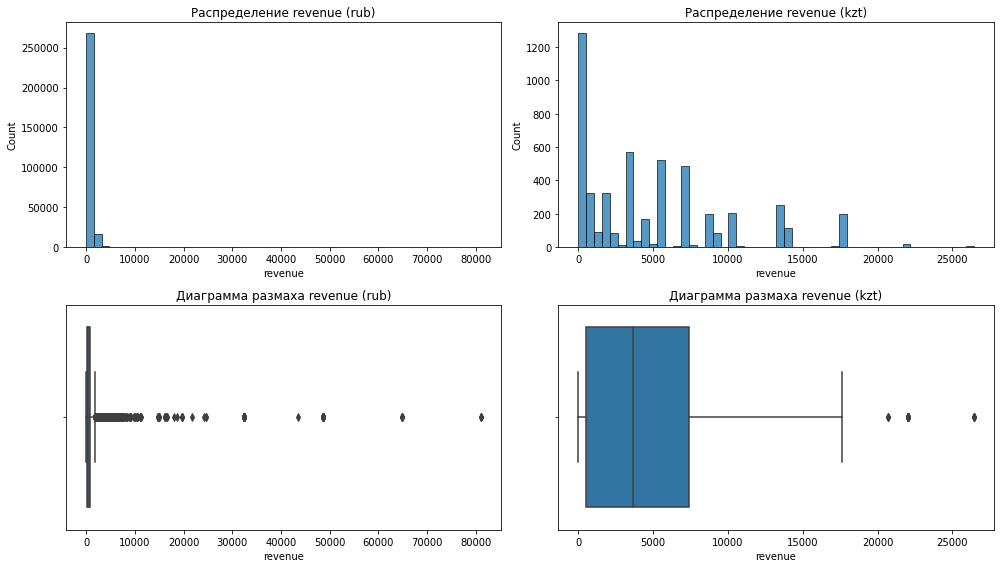

In [7]:
for cur in ['rub', 'kzt']:
    print(f'--- {cur}')
    print(df.loc[df['currency_code'] == cur, 'revenue'].describe(percentiles=[0.95, 0.99]).round(2))
    print()

print(df['tickets_count'].describe(percentiles=[0.99]))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, cur in enumerate(['rub', 'kzt']):
    part = df[df['currency_code'] == cur]
    sns.histplot(part['revenue'], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f'Распределение revenue ({cur})')
    sns.boxplot(x=part['revenue'], ax=axes[1, i])
    axes[1, i].set_title(f'Диаграмма размаха revenue ({cur})')
plt.tight_layout()
plt.show()

### 2.6. Фильтрация выбросов
Отбираем значения выручки по 99-му процентилю отдельно для каждой валюты.

In [8]:
rows_before = len(df)
p99 = df.groupby('currency_code')['revenue'].transform(lambda s: s.quantile(0.99))
df = df[df['revenue'] <= p99].reset_index(drop=True)

print(f'Удалено выбросов: {rows_before - len(df)}')
print(df['currency_code'].value_counts())

Удалено выбросов: 2885
rub    282647
kzt      5039
Name: currency_code, dtype: int64


### 2.7. Создание новых столбцов
Приводим выручку к рублям и добавляем выручку с одного билета, месяц и сезон заказа.

In [9]:
tenge['data'] = pd.to_datetime(tenge['data'])
df = df.merge(tenge[['data', 'curs', 'nominal']], left_on='created_dt_msk', right_on='data', how='left')

# курс задан за 100 тенге
df['revenue_rub'] = np.where(df['currency_code'] == 'kzt', df['revenue'] * df['curs'] / df['nominal'], df['revenue'])
df = df.drop(columns=['data', 'curs', 'nominal'])

df['one_ticket_revenue_rub'] = df['revenue_rub'] / df['tickets_count']
df['month'] = df['created_dt_msk'].dt.month

season_map = {12: 'зима', 1: 'зима', 2: 'зима',
              3: 'весна', 4: 'весна', 5: 'весна',
              6: 'лето', 7: 'лето', 8: 'лето',
              9: 'осень', 10: 'осень', 11: 'осень'}
df['season'] = df['month'].map(season_map)

print('Пропусков в revenue_rub:', df['revenue_rub'].isna().sum())
display(df[['currency_code', 'revenue', 'revenue_rub', 'tickets_count', 'one_ticket_revenue_rub', 'month', 'season']].sample(5, random_state=42))

Пропусков в revenue_rub: 0


,currency_code,revenue,revenue_rub,tickets_count,one_ticket_revenue_rub,month,season
224634,rub,1031.11,1031.11,3,343.703333,6,лето
198224,rub,0.49,0.49,1,0.490000,6,лето
202771,rub,16.76,16.76,1,16.760000,6,лето
203974,rub,924.14,924.14,3,308.046667,8,лето
100590,rub,116.99,116.99,3,38.996667,10,осень


### 2.8. Проверка итоговых данных
Оцениваем, сколько данных осталось после фильтрации, и проверяем период и охват.

In [10]:
print(f'Осталось строк: {len(df)}')
print(f'Доля от исходных заказов: {len(df) / len(orders):.1%}')
print('Период:', df['created_dt_msk'].min().date(), '-', df['created_dt_msk'].max().date())
print('Пользователей:', df['user_id'].nunique(), '| мероприятий:', df['event_id'].nunique())
print(df['season'].value_counts())

Осталось строк: 287686
Доля от исходных заказов: 98.9%
Период: 2024-06-01 - 2024-10-31
Пользователей: 21840 | мероприятий: 22359
осень    168580
лето     119106
Name: season, dtype: int64


### 2.9. Промежуточный вывод по предобработке

**Что сделано:**
- Пропуски есть только в `days_since_prev` (это первые заказы пользователей), остальные столбцы заполнены полностью.
- В категориальных столбцах скрытых пропусков нет. Значение `нет` в `cinema_circuit` означает «не применимо», а не пропуск. Неявных дубликатов в названиях билетных операторов, типах мероприятий и регионах не обнаружено.
- Таблицы объединены по `event_id`. 238 заказов не нашли пару в `events` — это фильмы, исключённые из выгрузки. Строки удалены, так как для них нет информации о типе мероприятия, региона и площадки.
- Типы данных: даты приведены к `datetime`, целочисленные столбцы понижены по размерности, что снизило объём занимаемой памяти.
- Явных дубликатов по `order_id` нет. Неявные дубликаты (одинаковые заказы без учёта `order_id`) составили 40 строк, они удалены как повторная запись одного бронирования.
- В `revenue` обнаружены выбросы (максимум в рублях около 81 тыс. при медиане около 347 руб.). Выбросы отброшены по 99-му проценту отдельно для рублей (порог около 2 571 руб.) и тенге (порог около 17 617 тенге).
- Столбец `revenue_rub` создан конвертацией тенге по курсу на дату заказа (курс задан за 100 тенге).
- В `tickets_count` медиана равна 3 билетам, 99-й процентиль — 6, максимум — 57. Единичные крупные заказы оставлены, так как по заданию выбросы отбираются по выручке.
- В `revenue` есть нулевые и отрицательные значения (минимум -90,76 руб.), вероятно возвраты и бесплатные билеты. Их оставили без изменений, так как отдельной обработки в задании нет.

**Новые столбцы:** `revenue_rub` — выручка в рублях, `one_ticket_revenue_rub` — выручка с одного билета, `month` — месяц заказа, `season` — сезон (лето/осень).

**Итог:** после предобработки осталось 287 686 заказов (98,9% от исходных 290 849). Данные охватывают период с июня по октябрь 2024 года: лето (июнь-август) и осень (сентябрь-октябрь).

## Шаг 3. Исследовательский анализ данных
### 3.1. Распределение заказов по сегментам и сезонные изменения

#### 3.1.1. Динамика заказов по месяцам
Считаем число заказов в каждом месяце и проверяем, растёт ли спрос от июня к осени.

month
6     34164
7     40403
8     44539
9     69320
10    99260
Name: order_id, dtype: int64


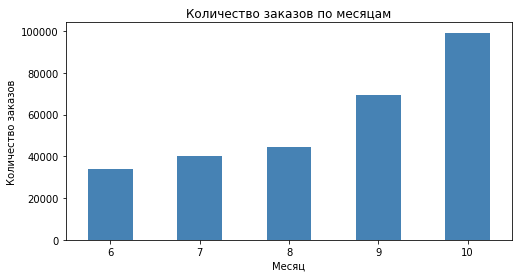

In [11]:
monthly = df.groupby('month')['order_id'].count()
print(monthly)

plt.figure(figsize=(8, 4))
monthly.plot(kind='bar', color='steelblue')
plt.title('Количество заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.xticks(rotation=0)
plt.show()

#### 3.1.2. Распределение заказов по сегментам: лето и осень
Сравниваем доли заказов летом и осенью по типу мероприятия, устройству и возрастному ограничению.

season,лето,осень,"разница, п.п."
event_type_main,,,
выставки,2.0,1.4,-0.6
другое,27.2,19.7,-7.5
концерты,42.6,37.2,-5.4
спорт,2.5,11.2,8.7
стендап,5.3,4.1,-1.2
театр,20.1,25.3,5.2
ёлки,0.2,1.0,0.8


season,лето,осень,"разница, п.п."
device_type_canonical,,,
desktop,19.4,20.3,1.0
mobile,80.6,79.7,-1.0


season,лето,осень,"разница, п.п."
age_limit,,,
0,18.0,23.6,5.7
6,18.2,17.6,-0.6
12,20.5,22.1,1.5
16,28.3,26.2,-2.1
18,15.0,10.4,-4.5


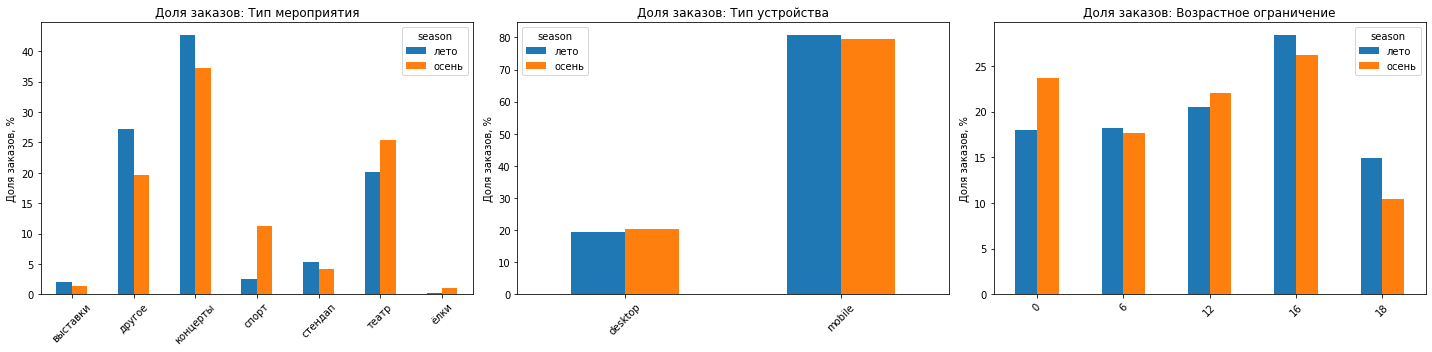

In [12]:
segments = {'event_type_main': 'Тип мероприятия',
            'device_type_canonical': 'Тип устройства',
            'age_limit': 'Возрастное ограничение'}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (col, title) in zip(axes, segments.items()):
    share = pd.crosstab(df[col], df['season'], normalize='columns')[['лето', 'осень']] * 100
    share.plot(kind='bar', ax=ax)
    ax.set_title(f'Доля заказов: {title}')
    ax.set_xlabel('')
    ax.set_ylabel('Доля заказов, %')
    ax.tick_params(axis='x', rotation=45)
    share['разница, п.п.'] = share['осень'] - share['лето']
    display(share.round(1))
plt.tight_layout()
plt.show()

#### 3.1.3. Изменение выручки с одного билета
Считаем среднюю выручку с одного билета по типам мероприятий летом и осенью и смотрим относительное изменение.

season,лето,осень,"изменение, %"
event_type_main,,,
театр,214.1,176.0,-17.8
ёлки,271.4,229.6,-15.4
концерты,304.7,268.1,-12.0
другое,77.4,76.1,-1.7
спорт,50.8,50.0,-1.6
выставки,86.4,90.6,4.8
стендап,218.5,231.1,5.8


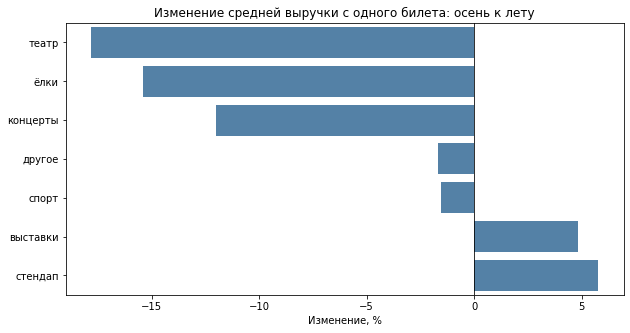

season
лето     209.2
осень    178.0
Name: one_ticket_revenue_rub, dtype: float64


In [13]:
price = df.groupby(['event_type_main', 'season'])['one_ticket_revenue_rub'].mean().unstack()[['лето', 'осень']]
price['изменение, %'] = (price['осень'] / price['лето'] - 1) * 100
price = price.sort_values('изменение, %')
display(price.round(1))

plt.figure(figsize=(10, 5))
sns.barplot(x=price['изменение, %'], y=price.index, color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Изменение средней выручки с одного билета: осень к лету')
plt.xlabel('Изменение, %')
plt.ylabel('')
plt.show()

print(df.groupby('season')['one_ticket_revenue_rub'].mean().round(1))

#### 3.1.4. Промежуточный вывод по разделу 3.1

**Динамика заказов.** Число заказов растёт каждый месяц: с 34 164 в июне до 99 260 в октябре (почти в 3 раза). Самый заметный скачок приходится на сентябрь (+56% к августу), в октябре рост продолжился (+43% к сентябрю). Данных за ноябрь нет, поэтому проверить рост до ноября нельзя — увеличение подтверждается для периода июнь-октябрь.

**Структура заказов (доли, лето -> осень):**
- Типы мероприятий: сильнее всего выросла доля спорта (2,5% -> 11,2%) и театра (20,1% -> 25,3%), также выросла доля ёлок (0,2% -> 1,0%). Доли категории «другое» (27,2% -> 19,7%) и концертов (42,6% -> 37,2%) снизились, но концерты остаются самым популярным типом.
- Устройства: распределение практически не изменилось — около 80% заказов делают с мобильных устройств, 20% со стационарных.
- Возрастные ограничения: выросла доля 0+ (18,0% -> 23,6%) и 12+ (20,5% -> 22,1%), снизилась доля 18+ (15,0% -> 10,4%) и 16+ (28,3% -> 26,2%). Осенью спрос смещается в сторону семейных и детских мероприятий.

**Выручка с одного билета.** Средняя выручка с билета в целом упала с 209,2 до 178,0 руб. (около -15%). По типам мероприятий: театр -17,8%, ёлки -15,4%, концерты -12,0%; практически не изменились спорт (-1,6%) и «другое» (-1,7%); выросли выставки (+4,8%) и стендап (+5,8%).

**Вывод.** Осенью растёт число заказов и меняется структура спроса: больше театра, спорта и детских мероприятий. Снижение средней стоимости билета связано как с удешевлением билетов на театр и концерты, так и со сдвигом структуры: растёт доля дешёвого спорта (около 50 руб. за билет) и падает доля дорогих концертов (около 270-300 руб.).

### 3.2. Осенняя активность пользователей

#### 3.2.1. Динамика активности по дням
Считаем по дням число заказов, DAU, заказы на одного пользователя и среднюю выручку с билета.

,orders,dau,avg_ticket_price,orders_per_user
count,61.00,61.00,61.00,61.00
mean,2763.61,923.39,183.10,2.96
std,967.91,143.40,21.79,0.76
min,1327.00,564.00,80.13,2.33
25%,2313.00,822.00,177.79,2.70
50%,2649.00,946.00,186.87,2.78
75%,2910.00,1025.00,196.21,2.91
max,7288.00,1272.00,208.77,6.63


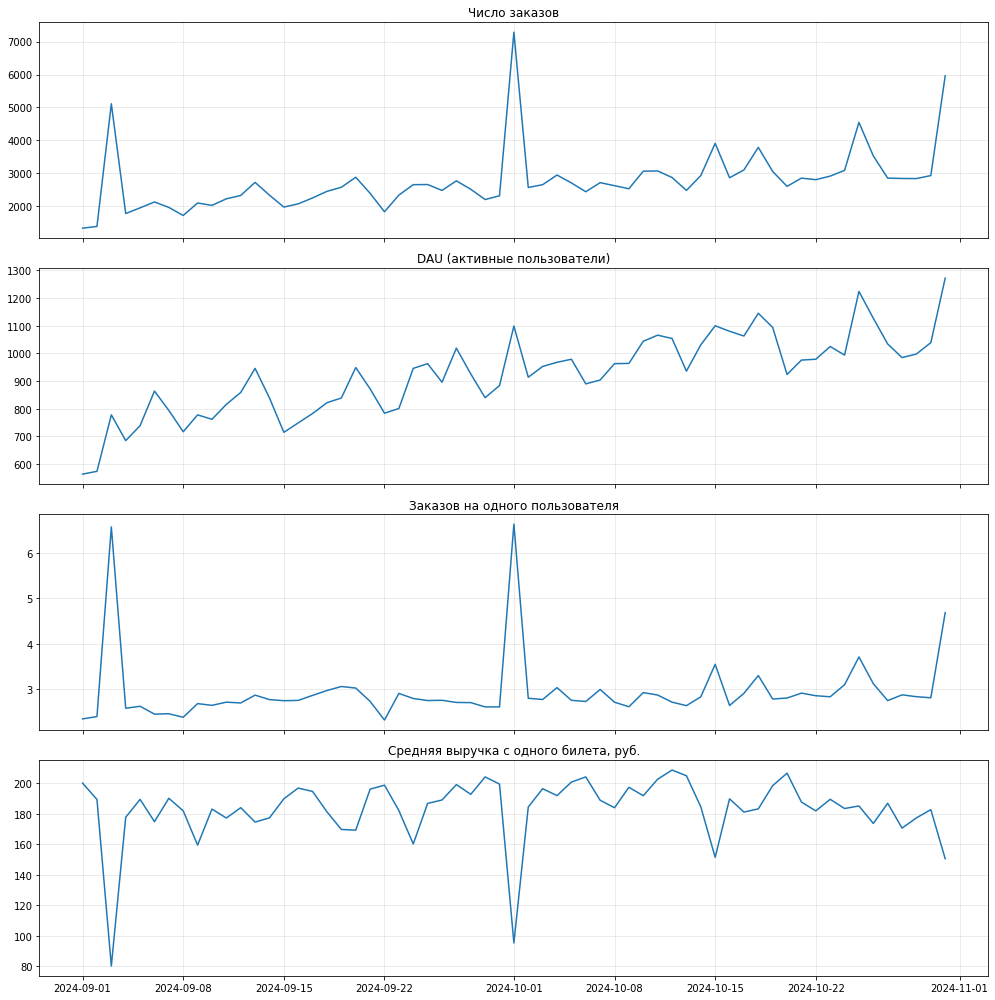

Первая неделя: {'orders': 2231.0, 'dau': 714.0}
Последняя неделя: {'orders': 3640.0, 'dau': 1097.0}
Медианный DAU, первые 30 дней: 819.0 | остальные дни: 1025.0


In [14]:
autumn = df[df['season'] == 'осень']

daily = autumn.groupby('created_dt_msk').agg(orders=('order_id', 'count'),
                                             dau=('user_id', 'nunique'),
                                             avg_ticket_price=('one_ticket_revenue_rub', 'mean'))
daily['orders_per_user'] = daily['orders'] / daily['dau']
display(daily.describe().round(2))

metrics = {'orders': 'Число заказов',
           'dau': 'DAU (активные пользователи)',
           'orders_per_user': 'Заказов на одного пользователя',
           'avg_ticket_price': 'Средняя выручка с одного билета, руб.'}

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=True)
for ax, (col, title) in zip(axes, metrics.items()):
    ax.plot(daily.index, daily[col])
    ax.set_title(title)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print('Первая неделя:', daily.iloc[:7][['orders', 'dau']].mean().round(0).to_dict())
print('Последняя неделя:', daily.iloc[-7:][['orders', 'dau']].mean().round(0).to_dict())
print('Медианный DAU, первые 30 дней:', daily['dau'].iloc[:30].median(), '| остальные дни:', daily['dau'].iloc[30:].median())

#### 3.2.2. Аномальные дни
Проверяем, что стоит за днями с резким всплеском заказов.

In [15]:
for day in daily['orders'].nlargest(3).index:
    day_orders = autumn[autumn['created_dt_msk'] == day]
    print(day.date(), 'заказов:', len(day_orders))
    print('типы:', day_orders['event_type_main'].value_counts(normalize=True).head(2).round(2).to_dict())
    print('регионы:', day_orders['region_name'].value_counts(normalize=True).head(2).round(2).to_dict())
    print('операторы:', day_orders['service_name'].value_counts(normalize=True).head(2).round(2).to_dict())
    print()

2024-10-01 заказов: 7288
типы: {'спорт': 0.67, 'концерты': 0.15}
регионы: {'Медовская область': 0.65, 'Каменевский регион': 0.1}
операторы: {'Билеты в руки': 0.67, 'Билеты без проблем': 0.07}

2024-10-31 заказов: 5961
типы: {'концерты': 0.66, 'театр': 0.13}
регионы: {'Каменевский регион': 0.59, 'Североярская область': 0.12}
операторы: {'Мой билет': 0.53, 'Лови билет!': 0.1}

2024-09-03 заказов: 5111
типы: {'спорт': 0.72, 'концерты': 0.11}
регионы: {'Медовская область': 0.7, 'Каменевский регион': 0.07}
операторы: {'Билеты в руки': 0.73, 'Билеты без проблем': 0.08}



#### 3.2.3. Недельная цикличность
Сравниваем активность по дням недели, в будни и в выходные (используем медианы, чтобы пики не искажали картину).

,orders,dau,orders_per_user,avg_ticket_price
Пн,2333.0,884.0,2.84,187.76
Вт,2802.0,963.0,2.86,177.37
Ср,2565.0,963.0,2.76,184.51
Чт,2649.0,953.0,2.91,184.06
Пт,2909.5,993.5,2.95,184.23
Сб,2606.5,952.5,2.75,194.52
Вс,2198.0,840.0,2.64,200.17


,orders,dau,orders_per_user,avg_ticket_price
day_type,,,,
будни,2715.5,958.0,2.84,183.77
выходные,2435.0,890.0,2.74,198.54


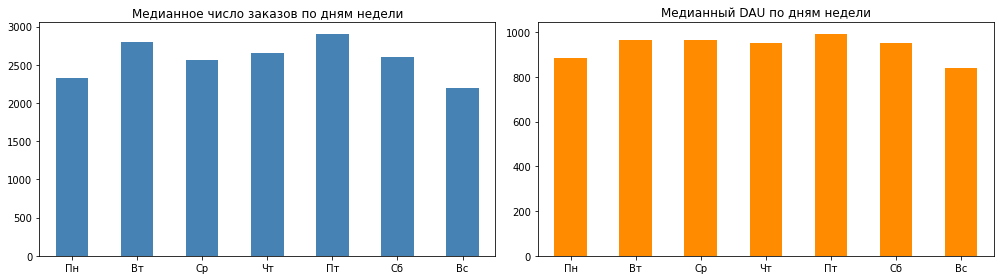

In [16]:
daily['weekday'] = daily.index.dayofweek
daily['day_type'] = np.where(daily['weekday'] >= 5, 'выходные', 'будни')
cols = ['orders', 'dau', 'orders_per_user', 'avg_ticket_price']

by_weekday = daily.groupby('weekday')[cols].median().round(2)
by_weekday.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
display(by_weekday)
display(daily.groupby('day_type')[cols].median().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_weekday['orders'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Медианное число заказов по дням недели')
by_weekday['dau'].plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Медианный DAU по дням недели')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

#### 3.2.4. Промежуточный вывод по разделу 3.2
**Динамика за сентябрь-октябрь (61 день).**
- Число заказов и DAU растут: в среднем за первую неделю сентября было около 2 230 заказов и 714 активных пользователей в день, за последнюю неделю октября — около 3 640 заказов и 1 097 пользователей. Медианный DAU вырос с 819 в первые 30 дней до 1 025 в оставшиеся дни.
- Среднее число заказов на одного пользователя в обычные дни стабильно: медиана 2,78 (обычно 2,3-3,0).
- Средняя выручка с одного билета держится около 183 руб. (медиана 187 руб.) без выраженного тренда.

**Аномальные дни.** Три дня резко выбиваются по числу заказов: 3 сентября (5 111), 1 октября (7 288) и 31 октября (5 961). В первых двух 67-72% заказов — спорт, около 65-70% приходится на Медовскую область, а 67-73% — на оператора «Билеты в руки». В эти дни число заказов на пользователя вырастает до 6,6, а средняя выручка с билета падает до 80 руб. (3 сентября). Это похоже на массовую продажу дешёвых билетов на спортивные события одним партнёром. 31 октября пик другой природы: 66% заказов — концерты, 59% — Каменевский регион. Эти дни искажают средние значения, поэтому далее используются медианы. Пики спортивных заказов также объясняют рост доли спорта осенью и часть снижения средней стоимости билета.

**Недельная цикличность.** Пользователи активнее в будни, чем в выходные: медианное число заказов 2 716 против 2 435, DAU 958 против 890. Самый слабый день — воскресенье (2 198 заказов, DAU 840), самый сильный — пятница (2 910 заказов, DAU 994). При этом в выходные билеты в среднем дороже (около 199 руб. против 184 руб. в будни).

### 3.3. Популярные события и партнёры
#### 3.3.1. Распределение мероприятий и заказов по регионам
Для каждого региона считаем число уникальных мероприятий и заказов, а также их доли от общего числа (по всему периоду).

,events,orders,"events_share, %","orders_share, %"
region_name,,,,
Каменевский регион,5935,89662,26.54,31.17
Североярская область,3800,43738,17.00,15.20
Широковская область,1232,16169,5.51,5.62
Светополянский округ,1075,7501,4.81,2.61
Речиновская область,702,6266,3.14,2.18
Травяная область,683,5036,3.05,1.75
Горицветская область,551,5152,2.46,1.79
Серебринская область,541,5586,2.42,1.94
Яблоневская область,535,6123,2.39,2.13


,events,orders,"events_share, %","orders_share, %"
region_name,,,,
Каменевский регион,5935,89662,26.54,31.17
Североярская область,3800,43738,17.00,15.20
Широковская область,1232,16169,5.51,5.62
Медовская область,504,13892,2.25,4.83
Озернинский край,349,10348,1.56,3.60


Регионов: 81
Доля топ-3 по мероприятиям, %: 49.0
Доля топ-3 по заказам, %: 52.0


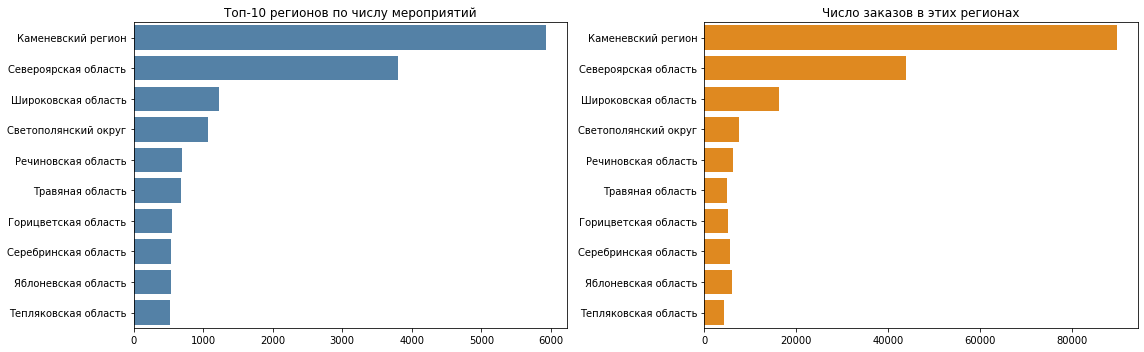

In [17]:
regions = df.groupby('region_name').agg(events=('event_id', 'nunique'),
                                        orders=('order_id', 'count'))
regions['events_share, %'] = regions['events'] / df['event_id'].nunique() * 100
regions['orders_share, %'] = regions['orders'] / len(df) * 100
regions = regions.sort_values('events', ascending=False)
display(regions.head(10).round(2))
display(regions.sort_values('orders', ascending=False).head(5).round(2))

print('Регионов:', len(regions))
print('Доля топ-3 по мероприятиям, %:', regions['events_share, %'].head(3).sum().round(1))
print('Доля топ-3 по заказам, %:', regions.sort_values('orders', ascending=False)['orders_share, %'].head(3).sum().round(1))

top_regions = regions.head(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_regions['events'], y=top_regions.index, color='steelblue', ax=axes[0])
axes[0].set_title('Топ-10 регионов по числу мероприятий')
sns.barplot(x=top_regions['orders'], y=top_regions.index, color='darkorange', ax=axes[1])
axes[1].set_title('Число заказов в этих регионах')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

#### 3.3.2. Распределение по билетным партнёрам
Для каждого билетного оператора считаем число уникальных мероприятий, заказов и суммарную выручку в рублях, а также доли от общих значений.

,events,orders,revenue,"orders_share, %","revenue_share, %"
service_name,,,,,
Билеты без проблем,4247,62830,24255224.25,21.84,16.27
Мой билет,1300,34439,22042027.60,11.97,14.78
Облачко,2335,26402,18588613.86,9.18,12.47
Лови билет!,4867,40798,16668711.96,14.18,11.18
Весь в билетах,855,16409,16493784.46,5.70,11.06
Билеты в руки,3530,40279,13193688.88,14.00,8.85
Край билетов,252,6109,6405689.22,2.12,4.30
Прачечная,1026,10222,4746810.52,3.55,3.18
Дом культуры,272,4412,4358655.99,1.53,2.92


Партнёров: 36
Партнёров с долей заказов меньше 1%: 24
Суммарная выручка, млн руб.: 149.1
Доля топ-5 по выручке, %: 65.8
Доля топ-5 по заказам, %: 71.2


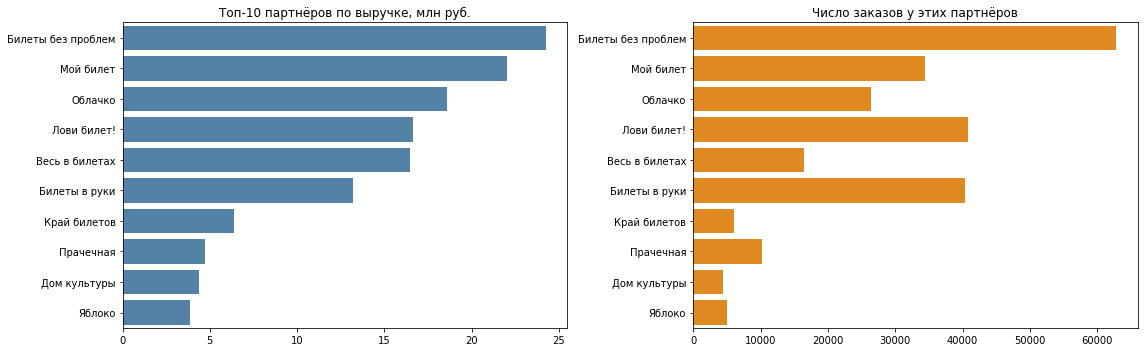

In [18]:
partners = df.groupby('service_name').agg(events=('event_id', 'nunique'),
                                         orders=('order_id', 'count'),
                                         revenue=('revenue_rub', 'sum'))
partners['orders_share, %'] = partners['orders'] / len(df) * 100
partners['revenue_share, %'] = partners['revenue'] / df['revenue_rub'].sum() * 100
partners = partners.sort_values('revenue', ascending=False)
display(partners.head(10).round(2))

print('Партнёров:', len(partners))
print('Партнёров с долей заказов меньше 1%:', (partners['orders_share, %'] < 1).sum())
print('Суммарная выручка, млн руб.:', round(df['revenue_rub'].sum() / 1e6, 1))
print('Доля топ-5 по выручке, %:', partners['revenue_share, %'].head(5).sum().round(1))
print('Доля топ-5 по заказам, %:', partners['orders_share, %'].sort_values(ascending=False).head(5).sum().round(1))

top_partners = partners.head(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_partners['revenue'] / 1e6, y=top_partners.index, color='steelblue', ax=axes[0])
axes[0].set_title('Топ-10 партнёров по выручке, млн руб.')
sns.barplot(x=top_partners['orders'], y=top_partners.index, color='darkorange', ax=axes[1])
axes[1].set_title('Число заказов у этих партнёров')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

#### 3.3.3. Промежуточный вывод по разделу 3.3

**Регионы.** Данные охватывают 81 регион, но мероприятия и заказы сильно сконцентрированы. На три региона приходится 49,0% всех мероприятий и 52,0% заказов. Явные лидеры — Каменевский регион (5 935 мероприятий, 26,5%; 89 662 заказов, 31,2%) и Североярская область (3 800 мероприятий, 17,0%; 43 738 заказов, 15,2%), третье место занимает Широковская область (5,5% мероприятий, 5,6% заказов). Остальные регионы дают небольшие доли, и ни один из них не выходит за 5% мероприятий. Отдельно выделяется Медовская область: при небольшом числе мероприятий (504, 2,3%) в ней 13 892 заказа (4,8%), то есть на одно мероприятие приходится заметно больше заказов, чем в среднем.

**Партнёры.** В данных 36 билетных операторов. На пятёрку лидеров приходится 65,8% выручки и 71,2% заказов. По выручке лидирует «Билеты без проблем» (24,3 млн руб., 16,3% выручки, 21,8% заказов), за ним идут «Мой билет» (22,0 млн руб., 14,8%), «Облачко» (18,6 млн руб., 12,5%), «Лови билет!» (16,7 млн руб., 11,2%) и «Весь в билетах» (16,5 млн руб., 11,1%). «Лови билет!» работает с наибольшим числом мероприятий (4 867). У операторов разный средний чек: у «Билеты в руки» доля заказов (14,0%) заметно выше доли выручки (8,9%) — это оператор дешёвых билетов, а у «Мой билет» наоборот (12,0% заказов и 14,8% выручки). 24 из 36 операторов дают менее 1% заказов каждый (вместе около 6%).

**Вывод.** Рынок неравномерен: два региона и несколько партнёров формируют большую часть заказов и выручки. Разнообразие мероприятий выше всего в Каменевском регионе и Североярской области.

## Шаг 4. Статистический анализ данных
### 4.1. Подготовка данных
Проверяем две гипотезы об отличии поведения пользователей мобильных и стационарных устройств. Используем только осенние данные. Единица анализа — пользователь. Чтобы группы были независимыми, исключаем пользователей, которые осенью заказывали с обоих типов устройств. Уровень значимости принимаем равным 0,05.

In [19]:
alpha = 0.05
autumn = df[df['season'] == 'осень']

# пользователи, которые заказывали только с одного типа устройств
devices_per_user = autumn.groupby('user_id')['device_type_canonical'].nunique()
both_devices = (devices_per_user > 1).sum()
print(f'Пользователей осенью: {len(devices_per_user)}')
print(f'Пользовались обоими устройствами: {both_devices} ({both_devices / len(devices_per_user):.1%})')

single_users = devices_per_user[devices_per_user == 1].index
autumn_single = autumn[autumn['user_id'].isin(single_users)]
print(autumn_single.groupby('device_type_canonical')['user_id'].nunique())

Пользователей осенью: 15808
Пользовались обоими устройствами: 3248 (20.5%)
device_type_canonical
desktop     1620
mobile     10940
Name: user_id, dtype: int64


### 4.2. Гипотеза 1: число заказов на одного пользователя

**Н0:** среднее число заказов на одного пользователя мобильных и стационарных устройств одинаково.
**Н1:** среднее число заказов на одного пользователя мобильных устройств больше.

Сначала смотрим на распределения.

,count,mean,std,min,50%,90%,99%,max
device_type_canonical,,,,,,,,
desktop,1620.0,1.97,3.06,1.0,1.0,3.0,12.00,56.0
mobile,10940.0,2.86,4.10,1.0,2.0,6.0,19.61,123.0


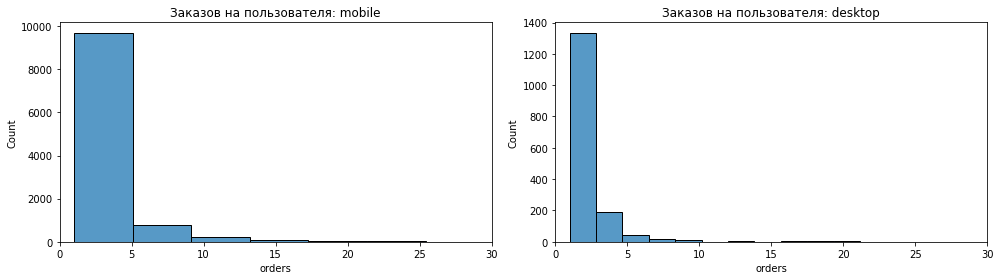

In [20]:
user_orders = (autumn_single.groupby(['user_id', 'device_type_canonical'])['order_id']
               .count().reset_index(name='orders'))
display(user_orders.groupby('device_type_canonical')['orders'].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for dev, ax in zip(['mobile', 'desktop'], axes):
    sns.histplot(user_orders.loc[user_orders['device_type_canonical'] == dev, 'orders'], bins=30, ax=ax)
    ax.set_title(f'Заказов на пользователя: {dev}')
    ax.set_xlim(0, 30)
plt.tight_layout()
plt.show()

**Выбор теста.** Гипотеза о средних, группы независимы (пользователи не пересекаются) и большие (тысячи наблюдений), поэтому по центральной предельной теореме подходит t-тест. Распределения скошены вправо, а дисперсии, судя по тесту Левена, различаются, поэтому используем t-тест Уэлча (`equal_var=False`) с односторонней альтернативой. Для проверки устойчивости результата дополнительно применяем непараметрический тест Манна-Уитни.

In [21]:
mobile_orders = user_orders.loc[user_orders['device_type_canonical'] == 'mobile', 'orders']
desktop_orders = user_orders.loc[user_orders['device_type_canonical'] == 'desktop', 'orders']
print('Тест Левена:', stats.levene(mobile_orders, desktop_orders))

t_res = stats.ttest_ind(mobile_orders, desktop_orders, equal_var=False, alternative='greater')
u_res = stats.mannwhitneyu(mobile_orders, desktop_orders, alternative='greater')
print(f'Среднее: mobile {mobile_orders.mean():.2f}, desktop {desktop_orders.mean():.2f}')
print(f'Welch t-test: p-value = {t_res.pvalue:.2e}')
print(f'Mann-Whitney U: p-value = {u_res.pvalue:.2e}')
print('Отвергаем H0' if t_res.pvalue < alpha else 'Не отвергаем H0')

Тест Левена: LeveneResult(statistic=78.34128639313919, pvalue=9.821067849364982e-19)
Среднее: mobile 2.86, desktop 1.97
Welch t-test: p-value = 7.38e-25
Mann-Whitney U: p-value = 4.68e-39
Отвергаем H0


### 4.3. Гипотеза 2: время между заказами

**Н0:** среднее время между заказами пользователей мобильных и стационарных устройств одинаково.
**Н1:** среднее время между заказами пользователей мобильных устройств больше.

Для каждого пользователя считаем среднее значение `days_since_prev` (пропуски — первые заказы — не учитываются).

,count,mean,std,min,50%,90%,99%,max
device_type_canonical,,,,,,,,
desktop,894.0,31.36,36.56,0.0,16.0,87.0,130.00,146.0
mobile,7055.0,25.25,30.21,0.0,14.0,69.8,126.46,148.0


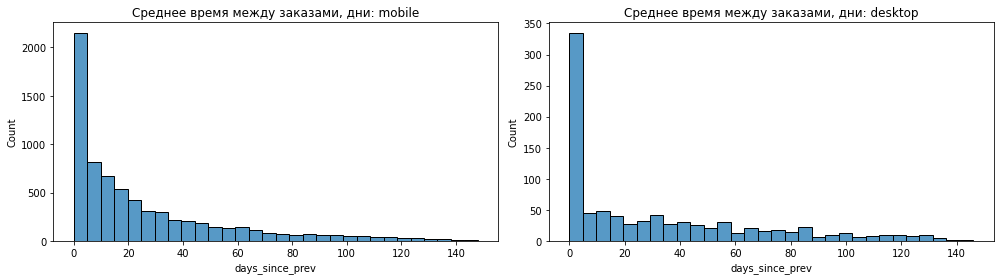

In [22]:
user_gap = (autumn_single.dropna(subset=['days_since_prev'])
            .groupby(['user_id', 'device_type_canonical'])['days_since_prev']
            .mean().reset_index())
display(user_gap.groupby('device_type_canonical')['days_since_prev'].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for dev, ax in zip(['mobile', 'desktop'], axes):
    sns.histplot(user_gap.loc[user_gap['device_type_canonical'] == dev, 'days_since_prev'], bins=30, ax=ax)
    ax.set_title(f'Среднее время между заказами, дни: {dev}')
plt.tight_layout()
plt.show()

**Выбор теста.** Логика та же, что и в первой гипотезе: независимые большие группы, скошенные распределения и разные дисперсии — применяем t-тест Уэлча с односторонней альтернативой, а для проверки устойчивости — тест Манна-Уитни.

In [23]:
mobile_gap = user_gap.loc[user_gap['device_type_canonical'] == 'mobile', 'days_since_prev']
desktop_gap = user_gap.loc[user_gap['device_type_canonical'] == 'desktop', 'days_since_prev']
print('Тест Левена:', stats.levene(mobile_gap, desktop_gap))

t_res = stats.ttest_ind(mobile_gap, desktop_gap, equal_var=False, alternative='greater')
u_res = stats.mannwhitneyu(mobile_gap, desktop_gap, alternative='greater')
print(f'Среднее: mobile {mobile_gap.mean():.2f}, desktop {desktop_gap.mean():.2f}')
print(f'Медиана: mobile {mobile_gap.median():.1f}, desktop {desktop_gap.median():.1f}')
print(f'Welch t-test: p-value = {t_res.pvalue:.4f}')
print(f'Mann-Whitney U: p-value = {u_res.pvalue:.4f}')
print('Отвергаем H0' if t_res.pvalue < alpha else 'Не отвергаем H0')

Тест Левена: LeveneResult(statistic=69.41215168844195, pvalue=9.32909845733713e-17)
Среднее: mobile 25.25, desktop 31.36
Медиана: mobile 14.0, desktop 16.0
Welch t-test: p-value = 1.0000
Mann-Whitney U: p-value = 0.7998
Не отвергаем H0


### 4.4. Промежуточный вывод по проверке гипотез

Из 15 808 осенних пользователей 3 248 (20,5%) пользовались обоими типами устройств, их исключили. В анализе остались 10 940 пользователей мобильных и 1 620 пользователей стационарных устройств.

**Гипотеза 1 подтверждена.** Мобильные пользователи в среднем делают 2,86 заказа за осень, пользователи стационарных устройств — 1,97 (медианы 2 и 1). Оба теста дают p-value существенно ниже 0,05 (t-тест Уэлча: 7,4e-25, Манна-Уитни: 4,7e-39), нулевую гипотезу отвергаем: пользователи мобильных устройств заказывают чаще.

**Гипотеза 2 не подтверждена.** Среднее время между заказами у мобильных пользователей составляет 25,3 дня (медиана 14), у пользователей стационарных устройств — 31,4 дня (медиана 16), то есть у мобильных оно не больше, а меньше. P-value в обоих тестах (около 1,0 и 0,80) намного выше 0,05, поэтому нулевую гипотезу не отвергаем. Полученные результаты согласуются с первой гипотезой: мобильные пользователи не только заказывают больше, но и возвращаются быстрее.

# Общий вывод и рекомендации

**Данные.** Исследованы заказы билетов Яндекс Афиши с 1 июня по 31 октября 2024 года с мобильных и стационарных устройств, информация о мероприятиях и курс тенге. После предобработки (удалены 238 заказов на фильмы, 40 неявных дубликатов и 2 885 выбросов выручки по 99-му процентилю, выручка в тенге переведена в рубли) осталось 287 686 заказов (98,9% от исходных). Выручка составила около 149 млн руб.

**Основные результаты.**
- **Рост спроса.** Число заказов выросло с 34 тыс. в июне до 99 тыс. в октябре, особенно резко в сентябре (+56%) и октябре (+43%). Среднее число заказов в день растёт: DAU вырос примерно с 700 до 1 100 пользователей.
- **Востребованные мероприятия.** Концерты остаются самым популярным типом (37% заказов осенью), затем театр (25%). Осенью заметно выросли доли спорта (2,5% -> 11,2%), театра (20,1% -> 25,3%) и детских мероприятий (0+: 18,0% -> 23,6%), снизились доли «другого» и концертов.
- **Средний чек.** Средняя выручка с билета упала на 15% (209 -> 178 руб.). Подешевели билеты на театр (-17,8%), ёлки (-15,4%) и концерты (-12,0%), а дополнительно сказался рост доли дешёвого спорта.
- **Активность пользователей.** Около 80% заказов делается с мобильных устройств. В будни активность выше, чем в выходные (медианно 2 716 против 2 435 заказов в день), самый слабый день — воскресенье. В сентябре-октябре выделяются три аномальных дня (3 сентября, 1 и 31 октября) с резким ростом заказов: в первых двух 65-70% заказов — спорт в Медовской области через оператора «Билеты в руки».
- **Регионы и партнёры.** Явные лидеры: Каменевский регион и Североярская область (около 46% заказов вместе). Пять партнёров приносят 66% выручки, лидирует «Билеты без проблем».

**Гипотезы.** Подтверждена гипотеза о том, что пользователи мобильных устройств делают больше заказов (2,86 против 1,97). Гипотеза о более длинных интервалах между заказами у мобильных пользователей не подтвердилась: они возвращаются в среднем быстрее (25,3 против 31,4 дня).

**Рекомендации.**
1. Подготовиться к зимнему сезону: рост заказов продолжается, поэтому стоит заранее расширить предложение новогодних и детских мероприятий (рост ёлок и категорий 0+) и усилить продвижение театра.
2. Приоритет — мобильный канал: на него приходится около 80% заказов, а его пользователи активнее. Нужно развивать мобильное приложение и удобство покупки.
3. Контролировать всплески заказов. Дни с аномальной активностью (спорт, Медовская область, оператор «Билеты в руки») искажают средние показатели. Стоит выяснить причину (акция, массовая продажа и т. д.) и при расчёте метрик учитывать такие дни отдельно.
4. Снижать зависимость от нескольких регионов и партнёров: два региона дают около 46% заказов, пять операторов — 66% выручки. Стоит развивать другие регионы и работать с партнёрами, у которых высокий средний чек.
5. Следить за средним чеком: рост заказов сопровождается снижением цены билета, поэтому для роста выручки важно сохранять долю дорогих мероприятий (концерты, театр).